# Quickstart: social learning community detection

This notebook tours the `slcd` library. Install it with `pip install -e .` from the repository root; the plots also
need `matplotlib`.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np

import slcd

## 1. Communities in one line

`ser_communities` (Score-based Edge Reliability) returns a list of node sets, like the functions of
`networkx.algorithms.community`, so it plugs directly into NetworkX's quality measures.

In [2]:
G = nx.karate_club_graph()
communities = slcd.ser_communities(G, K=5, epsilon=0.2, h=0.1, n_runs=200, seed=0)
print(len(communities), "communities, sizes", sorted(map(len, communities), reverse=True))
print("modularity:", round(nx.community.modularity(G, communities), 3))

5 communities, sizes [14, 11, 5, 3, 1]
modularity: 0.429


## 2. Choosing the interaction gain $K$

Communities can only appear when $K \lambda_{N-1}(P) > 1$, where $\lambda_{N-1}$ is the second-largest eigenvalue
of $P = D^{-1}A$. `spectral_threshold` returns the critical gain $K^* = 1/\lambda_{N-1}$.

In [3]:
print("K* (karate) =", round(slcd.spectral_threshold(G), 3))
for K in (0.8, 1.5, 5):
    print(f"K = {K}: {len(slcd.ser_communities(G, K=K, epsilon=0.2, h=0.1, n_runs=100, seed=0))} communities")

K* (karate) = 1.124
K = 0.8: 1 communities
K = 1.5: 7 communities
K = 5: 5 communities


## 3. The dynamics itself

`opinion_dynamics` integrates $x(t+1) = x(t) + h\,(P\,s(x(t)) - x(t))$. Here we use a planted partition with
three blocks: each block polarizes towards $\pm 1$.

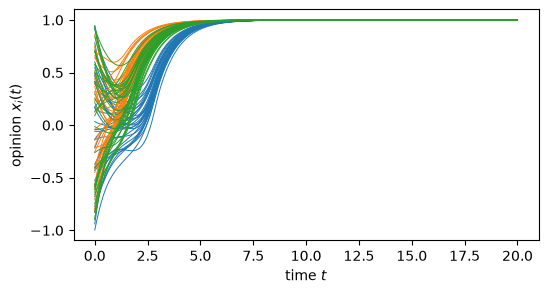

In [4]:
sizes = [30, 30, 30]
probs = np.full((3, 3), 0.02) + np.diag([0.4, 0.4, 0.4])
S = nx.stochastic_block_model(sizes, probs.tolist(), seed=1)
block = {v: b for b, nodes in enumerate(S.graph["partition"]) for v in nodes}

traj = slcd.opinion_dynamics(S, K=4, h=0.1, T=20, seed=3, record=True)
t = 0.1 * np.arange(traj.shape[1])
fig, ax = plt.subplots(figsize=(6, 3))
for v, row in zip(S, traj, strict=True):
    ax.plot(t, row, color=f"C{block[v]}", lw=0.7)
ax.set(xlabel="time $t$", ylabel="opinion $x_i(t)$")
plt.show()

## 4. Three algorithms

All three recover the planted partition.

In [5]:
truth = {frozenset(b) for b in S.graph["partition"]}
for name, algo in [
    ("SER", slcd.ser_communities),
    ("RNP", slcd.rnp_communities),
    ("RNP-DC", slcd.rnp_dc_communities),
]:
    found = {frozenset(c) for c in algo(S, seed=0)}
    print(f"{name:7s} {len(found)} communities, exact recovery: {found == truth}")

SER     3 communities, exact recovery: True
RNP     3 communities, exact recovery: True


RNP-DC  3 communities, exact recovery: True


## 5. Edge reliability as a fracture map

`ser_edge_reliability` returns, for every edge, the fraction of runs in which its endpoints agree. Low scores
reveal the bridges along which the network splits. `mode="opinion"` gives directed scores
$P_{i	o j}$ that compare the private opinion of $i$ with the public action of $j$.

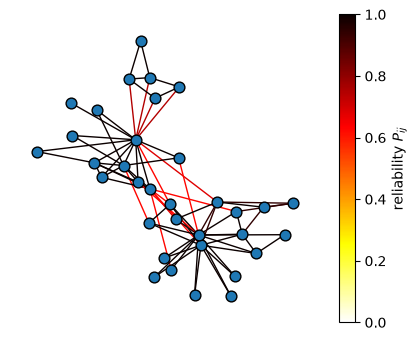

weakest ties: [(0, 8), (1, 30), (2, 8), (2, 9), (2, 27)]


In [6]:
P = slcd.ser_edge_reliability(G, K=5, epsilon=0.2, h=0.1, n_runs=300, seed=0)
pos = nx.spring_layout(G, seed=42)
fig, ax = plt.subplots(figsize=(5, 4))
edges = nx.draw_networkx_edges(
    G,
    pos,
    edgelist=list(P),
    edge_color=list(P.values()),
    edge_cmap=plt.cm.hot_r,
    edge_vmin=0,
    edge_vmax=1,
    ax=ax,
)
nx.draw_networkx_nodes(G, pos, node_size=60, edgecolors="k", ax=ax)
fig.colorbar(edges, ax=ax, label="reliability $P_{ij}$")
ax.axis("off")
plt.show()
print("weakest ties:", sorted(P, key=P.get)[:5])

## 6. Multi-plateau signals with RNP-DC

RNP-DC cuts edges during the transient phase, so communities can synchronize on *different* stable plateaus of a
staircase signal.

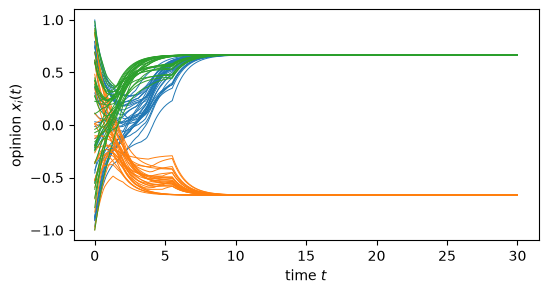

In [7]:
stair = slcd.signals.staircase(3)
traj = slcd.opinion_dynamics(S, K=2.5, h=0.1, T=30, signal=stair, confidence=(4.0, 0.98), seed=5, record=True)
fig, ax = plt.subplots(figsize=(6, 3))
for v, row in zip(S, traj, strict=True):
    ax.plot(0.1 * np.arange(len(row)), row, color=f"C{block[v]}", lw=0.7)
ax.set(xlabel="time $t$", ylabel="opinion $x_i(t)$")
plt.show()